## Rancangan Eksperimen

### Konsep singkat
- **Backbone (model pretrained):** model yang sudah "membaca" jutaan kalimat sehingga paham pola bahasa.
  Ibaratnya orang yang sudah fasih berbahasa, tapi belum pernah diminta menilai sentimen.
- **Head:** lapisan kecil di ujung model yang mengubah representasi kalimat menjadi 3 skor kelas.
  Head bawaan model dibuang dan diganti head baru dengan 3 output (*head replacement*).
- **Fine-tuning:** melatih ulang model pada data kita supaya cocok dengan tugas sentimen.
- **Freezing:** membekukan sebagian parameter (`requires_grad = False`) sehingga tidak ikut diperbarui.
  Lebih sedikit yang dilatih berarti lebih hemat waktu dan memori, tetapi model kurang bisa beradaptasi.
- **F1 makro vs akurasi:** data didominasi kelas positif (58%). Model yang selalu menebak "positif"
  pun sudah dapat akurasi 58%. F1 makro menghitung F1 tiap kelas lalu merata-ratakannya, sehingga
  kelas kecil (netral, 10%) dihitung sama pentingnya.
- **Seed dan simpangan baku antar-seed:** seed mengatur keacakan (inisialisasi head, urutan data).
  Seed berbeda bisa memberi hasil sedikit berbeda. Dengan 3 seed, kita bisa melihat seberapa besar
  variasi "kebetulan" itu, lalu membedakannya dari selisih yang benar-benar nyata.

### Hipotesis
- **H1 (backbone):** IndoBERT mencapai F1 makro tertinggi dibanding mBERT dan DistilBERT pada strategi
  yang sama, karena korpus pretraining dan kosakatanya selaras dengan Bahasa Indonesia.
  XLM-R diperkirakan bersaing dengan IndoBERT, dengan biaya parameter dan inferensi lebih besar.
- **H2 (strategi):** full > partial > probing pada F1 makro. Partial kehilangan sedikit F1 tetapi
  lebih hemat; probing paling hemat tetapi F1-nya jauh lebih rendah.
- **H3 (efisiensi):** DistilBERT sekitar 40% lebih kecil dan inferensinya 1,6–2× lebih cepat
  dibanding mBERT, dengan penurunan F1 makro yang kecil.

### Matriks eksperimen (24 run)
| Backbone \ Strategi | Full | Partial | Probing |
|---|---|---|---|
| mBERT | ✓ ×3 | ✓ ×3 | — |
| DistilBERT | ✓ ×3 | ✓ ×3 | — |
| IndoBERT | ✓ ×3 | ✓ ×3 | ✓ ×3 |
| XLM-R | ✓ ×3 | — | — |

### Variabel yang di gunakan
| Variabel | Nilai | Alasan |
|---|---|---|
| `max_length` | 128 | 99% kalimat ≤ 79 kata, jadi 128 token cukup tanpa banyak terpotong |
| Batch size | 32 | Ukuran umum untuk fine-tuning model base |
| Epoch | 3 | Rentang umum 2–4 epoch untuk fine-tuning |
| Seed | 42, 123, 2024 | Sama untuk semua run agar adil |
| Optimizer | AdamW, weight decay 0,01 | Standar fine-tuning Transformer |
| Scheduler | Linear, warmup 10% | LR naik perlahan di awal agar bobot pretrained tidak "kaget" |
| LR full/partial | 2e-5 | Kecil, karena bobot pretrained hanya perlu disesuaikan sedikit |
| LR probing | 1e-3 | Besar, karena hanya head baru (dari nol) yang dilatih |
| Presisi | fp16 bila GPU | Hemat memori dan waktu |  

### Alasan desain
- Label data uji SmSA disembunyikan, jadi **validasi resmi (yang dibersihkan) dipakai sebagai held-out**.
  Supaya tetap jujur, **tidak ada early stopping maupun pemilihan checkpoint** berdasarkan validasi.
  Setiap run dilatih dengan epoch tetap, lalu dievaluasi satu kali.
- Semua 24 run dijalankan dalam **satu sesi** di GPU yang sama, karena waktu inferensi hanya adil
  dibandingkan dalam kondisi yang sama.
- **Aturan menyimpulkan:** dua konfigurasi dianggap berbeda meyakinkan hanya jika selisih rata-ratanya
  lebih besar daripada simpangan baku antar-seed.

## Set-up Library

In [1]:
import os
import sys

# Paksa 1 GPU. Di Kaggle (T4 x2) ini mencegah DataParallel agar waktu sebanding.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false" # Mematikan peringatan 

import csv
import gc
import hashlib
import json
import platform
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

# cek GPU aja 
def cek_perangkat():
    if torch.cuda.is_available():
        properti_gpu = torch.cuda.get_device_properties(0)
        return {
            "device": "cuda",
            "gpu_name": properti_gpu.name,
            "vram_gb": properti_gpu.total_memory / (1024 ** 3),
        }
    return {"device": "cpu", "gpu_name": "-", "vram_gb": 0.0}


# folder utk menyimpan output dlm csv dan grafik nantinya
def tentukan_folder_output(is_kaggle):
    if is_kaggle:
        return Path("/kaggle/working")
    folder_sekarang = Path.cwd()
    # Jupyter menjalankan notebook dari folder notebooks/, jadi naik satu tingkat ke root repo.
    if folder_sekarang.name == "notebooks":
        return folder_sekarang.parent / "outputs"
    return folder_sekarang / "outputs"


# spill spek tipis-tipis
info_perangkat = cek_perangkat()
DEVICE = info_perangkat["device"]
GPU_NAME = info_perangkat["gpu_name"]
VRAM_GB = info_perangkat["vram_gb"]
USE_FP16 = DEVICE == "cuda"       
IS_KAGGLE = Path("/kaggle/working").exists()

# Folder output
OUTPUT_DIR = tentukan_folder_output(IS_KAGGLE)
FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Ringkasan
print("Environment")
print(f"  Platform     : {'Kaggle' if IS_KAGGLE else 'Lokal'}")
print(f"  Device       : {DEVICE}")
print(f"  GPU          : {GPU_NAME}")
print(f"  VRAM         : {VRAM_GB:.1f} GB")
print(f"  fp16         : {USE_FP16}")
if DEVICE == "cpu":
    print("GPU tidak terdeteksi.")

print("\nVERSI Library: ")
print(f"  Python       : {platform.python_version()}")
print(f"  torch        : {torch.__version__} (CUDA {torch.version.cuda})")
print(f"  transformers : {transformers.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  pandas       : {pd.__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  matplotlib   : {matplotlib.__version__}")

print("\nFOLDER OUTPUT")
print(f"  CSV    : {OUTPUT_DIR}")
print(f"  Grafik : {FIGURES_DIR}")

/home/sembiring/env/pytorch/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment
  Platform     : Lokal
  Device       : cuda
  GPU          : NVIDIA GeForce RTX 4050 Laptop GPU
  VRAM         : 5.6 GB
  fp16         : True

VERSI Library: 
  Python       : 3.14.4
  torch        : 2.13.0+cu132 (CUDA 13.2)
  transformers : 5.22.2
  scikit-learn : 1.9.0
  pandas       : 3.0.5
  numpy        : 2.5.2
  matplotlib   : 3.11.1

FOLDER OUTPUT
  CSV    : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs
  Grafik : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/figures


## KONFIGURASI

In [2]:
# ==== sedikit catatan utk menjalankan MODE ==== 
# "uji"   : cek kode dengan cepat (subset kecil, 1 epoch, 1 seed). Untuk laptop.
# "penuh" : eksperimen resmi 24 run dengan variabel terkendali di bawah. Untuk Kaggle.
MODE = "uji"

# utk MODE="uji"
UJI_BACKBONE = ["indobert"]
UJI_JUMLAH_DATA_LATIH = 500   # cukup untuk mengecek kode, bukan untuk hasil
UJI_EPOCH = 1
UJI_BATCH_SIZE = 8            # kecil agar aman di vram

# Variabel terkendali (mode penuh)
MAX_LENGTH = 128
BATCH_SIZE = 32
EPOCH = 3
SEEDS = [42, 123, 2024]
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1            # 10% dari total step dipakai untuk warmup
LR_PER_STRATEGI = {
    "full": 2e-5,
    "partial": 2e-5,
    "probing": 1e-3,          # lebih besar karena hanya head baru yang dilatih
}

# biaya waktu
INFER_JUMLAH_KALIMAT = 200    # sampel tetap dari validasi
INFER_JUMLAH_WARMUP = 10      # beberapa prediksi awal tidak dihitung (GPU masih "pemanasan")

# Backbone dan matriks eksperimen 
BACKBONES = {
    "mbert": "bert-base-multilingual-cased",
    "distilbert": "distilbert-base-multilingual-cased",
    "indobert": "indobenchmark/indobert-base-p1",
    "xlmr": "xlm-roberta-base",
}

# Strategi yang dijalankan untuk tiap backbone (sesuai matriks 24 run).
MATRIKS_EKSPERIMEN = {
    "mbert": ["full", "partial"],
    "distilbert": ["full", "partial"],
    "indobert": ["full", "partial", "probing"],
    "xlmr": ["full"],
}

## DAFTAR RUN DAN KODE KONFIGURASI

In [3]:
# Mengubah UJI_BACKBONE menjadi list kode backbone
def daftar_backbone_uji():
    if UJI_BACKBONE == "semua":
        return list(MATRIKS_EKSPERIMEN.keys())
    if isinstance(UJI_BACKBONE, str):
        return [UJI_BACKBONE]
    return list(UJI_BACKBONE)

# hentikan proses kalau isi konfigurasi ada yg salah
def validasi_konfigurasi():
    assert MODE in ("uji", "penuh"), f'MODE harus "uji" atau "penuh", bukan {MODE!r}'
    for backbone, daftar_strategi in MATRIKS_EKSPERIMEN.items():
        assert backbone in BACKBONES, f"Backbone '{backbone}' tidak ada di BACKBONES"
        for strategi in daftar_strategi:
            assert strategi in LR_PER_STRATEGI, f"Strategi '{strategi}' tidak punya learning rate"
    if MODE == "uji":
        for backbone in daftar_backbone_uji():
            assert backbone in MATRIKS_EKSPERIMEN, (
                f"UJI_BACKBONE berisi '{backbone}', pilihan yang ada: {list(MATRIKS_EKSPERIMEN)}"
            )
# Mengembalikan pengaturan yang berlaku untuk mode tertentu
def ambil_pengaturan_mode(mode):
    if mode == "penuh":
        return {
            "mode": "penuh",
            "backbones": list(MATRIKS_EKSPERIMEN.keys()),
            "seeds": SEEDS,
            "epoch": EPOCH,
            "batch_size": BATCH_SIZE,
            "subset_latih": None,          # None = pakai seluruh data latih
        }
    return {
        "mode": "uji",
        "backbones": daftar_backbone_uji(),
        "seeds": [SEEDS[0]],               # cukup 1 seed untuk mengecek kode
        "epoch": UJI_EPOCH,
        "batch_size": UJI_BATCH_SIZE,
        "subset_latih": UJI_JUMLAH_DATA_LATIH,
    }


def susun_daftar_run(pengaturan):
    daftar_run = []
    for backbone in pengaturan["backbones"]:
        for strategi in MATRIKS_EKSPERIMEN[backbone]:
            for seed in pengaturan["seeds"]:
                run = {
                    "run_id": f"{backbone}_{strategi}_s{seed}",
                    "backbone": backbone,
                    "checkpoint": BACKBONES[backbone],
                    "strategy": strategi,
                    "seed": seed,
                    "lr": LR_PER_STRATEGI[strategi],
                    "max_length": MAX_LENGTH,
                    "batch_size": pengaturan["batch_size"],
                    "epoch": pengaturan["epoch"],
                    "subset_latih": pengaturan["subset_latih"],
                    "mode": pengaturan["mode"],
                }
                daftar_run.append(run)
    return daftar_run

# Menghitung kode konfigurasi = 8 karakter pertama
def hitung_kode_konfigurasi(daftar_run):
    isi_konfigurasi = {
        "runs": daftar_run,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "infer_jumlah_kalimat": INFER_JUMLAH_KALIMAT,
        "infer_jumlah_warmup": INFER_JUMLAH_WARMUP,
    }
    teks_json = json.dumps(isi_konfigurasi, sort_keys=True)
    return hashlib.md5(teks_json.encode("utf-8")).hexdigest()[:8]


# Validasi konfigurasi
validasi_konfigurasi()

PENGATURAN = ambil_pengaturan_mode(MODE)
DAFTAR_RUN = susun_daftar_run(PENGATURAN)
KODE = hitung_kode_konfigurasi(DAFTAR_RUN)

if MODE == "penuh":
    assert len(DAFTAR_RUN) == 24, f"Mode penuh seharusnya 24 run, tetapi tersusun {len(DAFTAR_RUN)}"

HASIL_CSV = OUTPUT_DIR / f"hasil_smsa_{KODE}.csv"
REKAP_CSV = OUTPUT_DIR / f"rekap_agregat_smsa_{KODE}.csv"

print("=" * 60)
print("RINGKASAN KONFIGURASI")
print("=" * 60)
print(f"  MODE          : {MODE}")
print(f"  Backbone      : {PENGATURAN['backbones']}")
print(f"  Seed          : {PENGATURAN['seeds']}")
print(f"  Epoch         : {PENGATURAN['epoch']}")
print(f"  Batch size    : {PENGATURAN['batch_size']}")
print(f"  Data latih    : {'penuh' if PENGATURAN['subset_latih'] is None else PENGATURAN['subset_latih']}")
print(f"  Jumlah run    : {len(DAFTAR_RUN)}")
print(f"  Kode          : {KODE}")
print(f"  CSV hasil     : {HASIL_CSV}")
print(f"  CSV rekap     : {REKAP_CSV}")

kolom_tampil = ["run_id", "checkpoint", "strategy", "seed", "lr", "batch_size", "epoch"]
display(pd.DataFrame(DAFTAR_RUN)[kolom_tampil])

RINGKASAN KONFIGURASI
  MODE          : uji
  Backbone      : ['indobert']
  Seed          : [42]
  Epoch         : 1
  Batch size    : 8
  Data latih    : 500
  Jumlah run    : 3
  Kode          : f29f97ca
  CSV hasil     : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/hasil_smsa_f29f97ca.csv
  CSV rekap     : /home/sembiring/machine_learning/00_pr0j3ct/indo-sentiment-finetuning-benchmark/outputs/rekap_agregat_smsa_f29f97ca.csv


,run_id,checkpoint,strategy,seed,lr,batch_size,epoch
0,indobert_full_s42,indobenchmark/indobert-base-p1,full,42,0.00002,8,1
1,indobert_partial_s42,indobenchmark/indobert-base-p1,partial,42,0.00002,8,1
2,indobert_probing_s42,indobenchmark/indobert-base-p1,probing,42,0.00100,8,1


## Terkait Dataset 

#### Unduh dataset SmSA

**Apa yang dilakukan?** Mengunduh file data latih dan validasi SmSA dari repositori resmi IndoNLU
di GitHub, menyimpannya sementara di folder output, lalu membacanya menjadi tabel pandas.

**Kenapa perlu?**
- Data diambil langsung dari sumber resmi, jadi tidak perlu upload manual dan siapa pun bisa
  mereproduksi hasilnya. Di Kaggle, opsi **Internet harus On**.
- File berformat TSV (dipisah tab) **tanpa header**, dengan kolom `teks<TAB>label`.
  Dibaca dengan `quoting=csv.QUOTE_NONE` karena teksnya bisa mengandung tanda kutip (`"`).
  Tanpa opsi ini, pandas bisa salah mengira tanda kutip sebagai pembungkus kolom dan
  menggabungkan beberapa baris menjadi satu.
- Data uji resmi **tidak diunduh**, karena labelnya disembunyikan (semua tertulis "neutral")
  sehingga tidak bisa dipakai untuk evaluasi.

In [4]:
import urllib.request

# datset resmi yg diambil dari github
URL_DATA = {
    "latih": "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/train_preprocess.tsv",
    "validasi": "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/valid_preprocess.tsv",
}

# Urutan label ini dipakai di seluruh notebook (head model, F1 per kelas, confusion matrix).
LABEL_LIST = ["negative", "neutral", "positive"]
LABEL2ID = {}
ID2LABEL = {}
for indeks, nama_label in enumerate(LABEL_LIST):
    LABEL2ID[nama_label] = indeks
    ID2LABEL[indeks] = nama_label

# save datasetnya
DATA_DIR = OUTPUT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

def unduh_file(url, path_tujuan):
    if path_tujuan.exists():
        print(f"  Sudah ada: {path_tujuan.name}")
        return path_tujuan
    try:
        urllib.request.urlretrieve(url, path_tujuan)
        print(f"  Berhasil diunduh: {path_tujuan.name}")
    except Exception as error:
        raise RuntimeError(
            f"Gagal mengunduh {url}\n"
        ) from error
    return path_tujuan

# read dataframe
def baca_tsv_smsa(path_file):
    df = pd.read_csv(
        path_file,
        sep="\t",
        header=None,
        names=["text", "label"],
        quoting=csv.QUOTE_NONE,
        dtype=str,
        keep_default_na=False,
    )
    return df


print("Mengunduh data...")
path_latih = unduh_file(URL_DATA["latih"], DATA_DIR / "train_preprocess.tsv")
path_valid = unduh_file(URL_DATA["validasi"], DATA_DIR / "valid_preprocess.tsv")

data_latih_mentah = baca_tsv_smsa(path_latih)
data_valid_mentah = baca_tsv_smsa(path_valid)

# Pastikan tidak ada label di luar 3 kelas (misalnya akibat file rusak atau salah baca).
label_ditemukan = set(data_latih_mentah["label"]) | set(data_valid_mentah["label"])
assert label_ditemukan <= set(LABEL_LIST), f"Ada label tak dikenal: {label_ditemukan - set(LABEL_LIST)}"

print(f"\nData latih   : {len(data_latih_mentah)} baris")
print(f"Data validasi: {len(data_valid_mentah)} baris")
print(f"Label        : {sorted(label_ditemukan)}\n")
display(data_latih_mentah.head(5))

Mengunduh data...
  Sudah ada: train_preprocess.tsv
  Sudah ada: valid_preprocess.tsv

Data latih   : 11000 baris
Data validasi: 1260 baris
Label        : ['negative', 'neutral', 'positive']



,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


## Eksplorasi singkat

Data Train:


,jumlah,persen
label,,
negative,3436,31.2
neutral,1148,10.4
positive,6416,58.3



Data Validasi:


,jumlah,persen
label,,
negative,394,31.3
neutral,131,10.4
positive,735,58.3


PANJANG KALIMAT — data latih (dalam kata)
  median: 28
  p95   : 71
  p99   : 79
  maks  : 110

CONTOH KALIMAT PER LABEL
  [negative] duh . jadi mahasiswa jangan sombong dong . kasih kartu kuning segala . belajar dulu yang baik , tidak usahlah ikut-ikut politik . nanti sudah selesai 
  [neutral] mohon ulama lurus dan k212 mmbri hujjah partai apa yang harus diwlh agar suara islam tidak pecah-pecah
  [positive] warung ini dimiliki oleh pengusaha pabrik tahu yang sudah puluhan tahun terkenal membuat tahu putih di bandung . tahu berkualitas , dipadu keahlian me


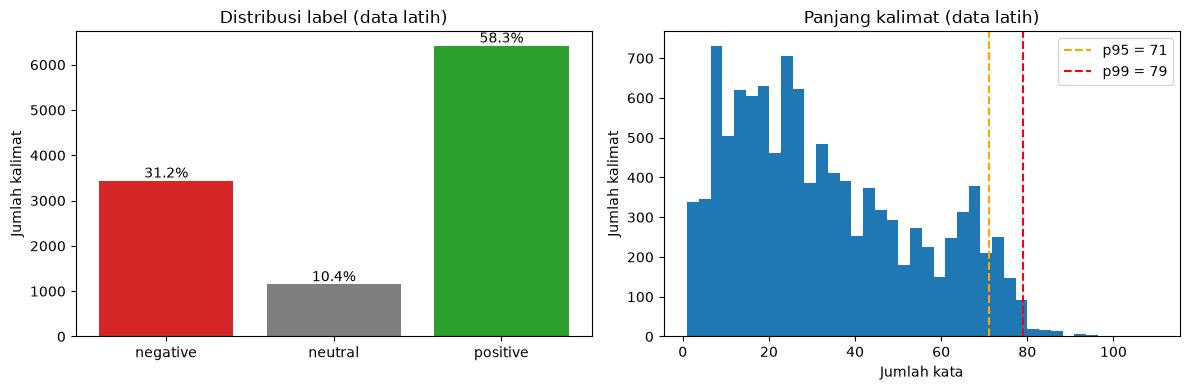

In [5]:
def tabel_distribusi_label(df):
    jumlah_per_label = df["label"].value_counts()
    tabel = pd.DataFrame({
        "jumlah": jumlah_per_label,
        "persen": (jumlah_per_label / len(df) * 100).round(1),
    })
    tabel = tabel.reindex(LABEL_LIST)
    return tabel


def hitung_jumlah_kata(df):
    kata_per_kalimat = df["text"].str.split()
    return kata_per_kalimat.str.len()


def ringkas_panjang_kalimat(jumlah_kata):
    return {
        "median": float(np.median(jumlah_kata)),
        "p95": float(np.percentile(jumlah_kata, 95)),
        "p99": float(np.percentile(jumlah_kata, 99)),
        "maks": int(jumlah_kata.max()),
    }


# Distribusi label 
print("Data Train:")
display(tabel_distribusi_label(data_latih_mentah))
print("\nData Validasi:")
display(tabel_distribusi_label(data_valid_mentah))

# Panjang kalimat 
jumlah_kata_latih = hitung_jumlah_kata(data_latih_mentah)
statistik_panjang = ringkas_panjang_kalimat(jumlah_kata_latih)
print("PANJANG KALIMAT — data latih (dalam kata)")
for nama, nilai in statistik_panjang.items():
    print(f"  {nama:<6}: {nilai:.0f}")

# Contoh kalimat per label
print("\nCONTOH KALIMAT PER LABEL")
for nama_label in LABEL_LIST:
    baris_label = data_latih_mentah[data_latih_mentah["label"] == nama_label]
    contoh_teks = baris_label["text"].iloc[0]
    print(f"  [{nama_label}] {contoh_teks[:150]}")


# visualisasi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
distribusi_latih = tabel_distribusi_label(data_latih_mentah)
axes[0].bar(distribusi_latih.index, distribusi_latih["jumlah"], color=["#d62728", "#7f7f7f", "#2ca02c"])
axes[0].set_title("Distribusi label (data latih)")
axes[0].set_ylabel("Jumlah kalimat")
for posisi, (jumlah, persen) in enumerate(zip(distribusi_latih["jumlah"], distribusi_latih["persen"])):
    axes[0].text(posisi, jumlah, f"{persen}%", ha="center", va="bottom")

axes[1].hist(jumlah_kata_latih, bins=40, color="#1f77b4")
axes[1].axvline(statistik_panjang["p95"], color="orange", linestyle="--", label=f"p95 = {statistik_panjang['p95']:.0f}")
axes[1].axvline(statistik_panjang["p99"], color="red", linestyle="--", label=f"p99 = {statistik_panjang['p99']:.0f}")
axes[1].set_title("Panjang kalimat (data latih)")
axes[1].set_xlabel("Jumlah kata")
axes[1].set_ylabel("Jumlah kalimat")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_smsa.png", dpi=150, bbox_inches="tight")
plt.show()

## Cleaning Dataset

#### Pembersihan data

**Apa yang dilakukan?** Tiga langkah pembersihan otomatis, dengan jumlah baris dicetak di setiap langkah:
1. **Buang duplikat persis**, yaitu baris dengan teks dan label yang sama persis. Duplikat membuat model
   "melihat" kalimat yang sama berkali-kali, sehingga kalimat itu terlalu berpengaruh.
2. **Buang teks berlabel bertentangan**, yaitu teks yang sama tetapi labelnya berbeda. Contoh seperti ini
   membingungkan model, dan kita tidak tahu label mana yang benar, jadi semua barisnya dibuang.
3. **Buang teks validasi yang juga ada di data latih** (*kebocoran data*). Kalau kalimat yang sama
   ada di kedua set, model hanya "mengingat", bukan benar-benar memahami. Akibatnya skor validasi
   terlihat lebih bagus dari kemampuan sebenarnya.

Langkah 1 dan 2 diterapkan ke data latih dan validasi. Langkah 3 hanya ke validasi.

Setelah itu, label teks diubah menjadi angka (`negative=0`, `neutral=1`, `positive=2`), karena model
hanya bisa bekerja dengan angka. Di `MODE="uji"`, data latih dipotong menjadi 500 baris secara
**stratified**, artinya proporsi ketiga label tetap sama seperti data aslinya.

In [6]:
from sklearn.model_selection import train_test_split

# utk data duplicate
def hapus_duplikat_persis(df):
    df_bersih = df.drop_duplicates(subset=["text", "label"], keep="first")
    return df_bersih, len(df) - len(df_bersih)

# buang data yang teksnya muncul lebih dari satu label
def hapus_label_bertentangan(df):
    jumlah_label_per_teks = df.groupby("text")["label"].nunique()
    teks_bertentangan = jumlah_label_per_teks[jumlah_label_per_teks > 1].index
    df_bersih = df[~df["text"].isin(teks_bertentangan)]
    return df_bersih, len(teks_bertentangan)

# hapus data yg leakage
def hapus_kebocoran_validasi(df_valid, df_latih):
    teks_latih = set(df_latih["text"])
    df_bersih = df_valid[~df_valid["text"].isin(teks_latih)]
    return df_bersih, len(df_valid) - len(df_bersih)

# membuat pembagian data dengan proposi sama banyak
def ambil_subset_stratified(df, jumlah, seed):
    df_subset, _ = train_test_split(
        df, train_size=jumlah, stratify=df["label"], random_state=seed
    )
    return df_subset


# utk data train
latih_1, jumlah_duplikat_latih = hapus_duplikat_persis(data_latih_mentah)
latih_2, jumlah_konflik_latih = hapus_label_bertentangan(latih_1)

# untuk data validasi
valid_1, jumlah_duplikat_valid = hapus_duplikat_persis(data_valid_mentah)
valid_2, jumlah_konflik_valid = hapus_label_bertentangan(valid_1)

# utk data yang bocor di hapus
valid_3, jumlah_bocor = hapus_kebocoran_validasi(valid_2, latih_2)


ringkasan_pembersihan = pd.DataFrame(
    {
        "latih": [len(data_latih_mentah), jumlah_duplikat_latih, jumlah_konflik_latih, 0, len(latih_2)],
        "validasi": [len(data_valid_mentah), jumlah_duplikat_valid, jumlah_konflik_valid, jumlah_bocor, len(valid_3)],
    },
    index=["awal", "duplikat dibuang", "teks label bertentangan", "teks bocor dibuang", "akhir"],
)
print("RINGKASAN PEMBERSIHAN")
display(ringkasan_pembersihan)

# Cek dengan angka yang sudah diverifikasi sebelumnya (peringatan saja, bukan error,
# karena data sumber bisa saja diperbarui oleh pemiliknya).
if len(latih_2) == 10933:
    print("Data latih bersih = 10933, sesuai verifikasi")
else:
    print(f"Data latih bersih = {len(latih_2)}, berbeda dari verifikasi (10933). Cek sumber data.")

# --- Ubah label teks menjadi angka ---
DATA_LATIH = latih_2.reset_index(drop=True).copy()
DATA_VALID = valid_3.reset_index(drop=True).copy()
DATA_LATIH["label_id"] = DATA_LATIH["label"].map(LABEL2ID)
DATA_VALID["label_id"] = DATA_VALID["label"].map(LABEL2ID)

# --- Subset untuk MODE="uji" ---
if PENGATURAN["subset_latih"] is not None:
    DATA_LATIH = ambil_subset_stratified(DATA_LATIH, PENGATURAN["subset_latih"], seed=SEEDS[0])
    DATA_LATIH = DATA_LATIH.reset_index(drop=True)
    print(f"\nMODE='uji': data latih dipotong menjadi {len(DATA_LATIH)} baris (stratified)")

# --- Hasil akhir ---
print(f"\nDATA_LATIH : {len(DATA_LATIH)} baris")
print(f"DATA_VALID : {len(DATA_VALID)} baris")
print("\nDistribusi label akhir — DATA_LATIH")
display(tabel_distribusi_label(DATA_LATIH))
print("Distribusi label akhir — DATA_VALID")
display(tabel_distribusi_label(DATA_VALID))
print("Contoh baris siap pakai:")
display(DATA_LATIH.head(3))

RINGKASAN PEMBERSIHAN


,latih,validasi
awal,11000,1260
duplikat dibuang,67,0
teks label bertentangan,0,0
teks bocor dibuang,0,14
akhir,10933,1246


Data latih bersih = 10933, sesuai verifikasi

MODE='uji': data latih dipotong menjadi 500 baris (stratified)

DATA_LATIH : 500 baris
DATA_VALID : 1246 baris

Distribusi label akhir — DATA_LATIH


,jumlah,persen
label,,
negative,156,31.2
neutral,52,10.4
positive,292,58.4


Distribusi label akhir — DATA_VALID


,jumlah,persen
label,,
negative,389,31.2
neutral,129,10.4
positive,728,58.4


Contoh baris siap pakai:


,text,label,label_id
0,"dengar dari teman tempat ini bagus , bisa buat...",negative,0
1,ahmad dani pengecut banget sih . tidak berani ...,negative,0
2,"mohon bantu viralkan man teman , biar si bangs...",negative,0


### Analisis
- Data latih: 11000 → **10933** (67 duplikat dibuang, 0 label bertentangan)
- Data validasi: 1260 → **sekitar 1246** (14 teks bocor dibuang; bisa berbeda sedikit kalau
  validasi juga punya duplikat)
- Distribusi label akhir. Di mode uji, data latih tercetak 500 baris dengan proporsi yang mirip.